In [1]:

%pip install -U qiskit qiskit-ibm-runtime qiskit[visualization] matplotlib pandas


Note: you may need to restart the kernel to use updated packages.


In [2]:

from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Enter your IBM Quantum instance CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Successfully connected to IBM Quantum!")


Enter your IBM Quantum API key:  ········
Enter your IBM Quantum instance CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/0222f50d31f44d74b2f0e9701c6f8bc2:d462f301-569a-42e8-b7b5-dbd297c94eae::


qiskit_runtime_service._discover_account:WARNING:2026-10-10 12:36:25,008: Loading account with the given token. A saved account will not be used.


Successfully connected to IBM Quantum!


In [3]:

backends = service.backends(
    simulator=False,
    operational=True
)

print("Available quantum computers:")
for b in backends:
    print(b.name)


Available quantum computers:
ibm_fez
ibm_kingston
ibm_marrakesh


In [4]:

backend = service.least_busy(
    operational=True,
    simulator=False
)

print("Selected backend:", backend.name)


Selected backend: ibm_fez


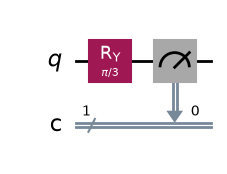

In [5]:

import math
from qiskit import QuantumCircuit

# Challenge 2: Make 0 more frequent
circuit_0 = QuantumCircuit(1, 1)

circuit_0.ry(math.pi / 3, 0)
circuit_0.measure(0, 0)

display(circuit_0.draw("mpl"))


In [6]:
#### Prediction — Circuit 1

#I predict that outcome 0 will occur more frequently than outcome 1.

#The RY(π/3) gate creates measurement probabilities of approximately 75% for 0 and 25% for 1. In 100 shots, I expect approximately 75 zeros and 25 ones. The actual counts may vary because of quantum randomness and hardware noise.

In [7]:

from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2

isa_circuit_0 = transpile(
    circuit_0,
    backend=backend,
    optimization_level=1
)

sampler = SamplerV2(mode=backend)

job_0 = sampler.run([isa_circuit_0], shots=100)

print("Job ID:", job_0.job_id())
print("Waiting for the hardware results...")

result_0 = job_0.result()
counts_0 = result_0[0].data.c.get_counts()

print("Actual measurement counts:", counts_0)


C:\Users\aksha\AppData\Local\Temp\ipykernel_44056\1048048596.py:10: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job ID: db4u8ekvf2bc73cv57b0
Waiting for the hardware results...
Actual measurement counts: {'0': 78, '1': 22}


In [9]:

from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

plot_histogram(
    counts_0,
    title="Biased Quantum Coin: 0 More Frequent"
)
plt.show()


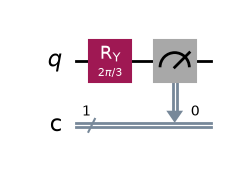

In [10]:

# Bonus circuit: Make 1 more frequent
circuit_1 = QuantumCircuit(1, 1)

circuit_1.ry(2 * math.pi / 3, 0)
circuit_1.measure(0, 0)

display(circuit_1.draw("mpl"))

# Predict before running:
# P(0) = 25%, P(1) = 75%


In [11]:

isa_circuit_1 = transpile(
    circuit_1,
    backend=backend,
    optimization_level=1
)

job_1 = sampler.run([isa_circuit_1], shots=100)

print("Job ID:", job_1.job_id())

result_1 = job_1.result()
counts_1 = result_1[0].data.c.get_counts()

print("Actual measurement counts:", counts_1)


Job ID: db4u9jo4qg6s73c2nid0
Actual measurement counts: {'1': 70, '0': 30}


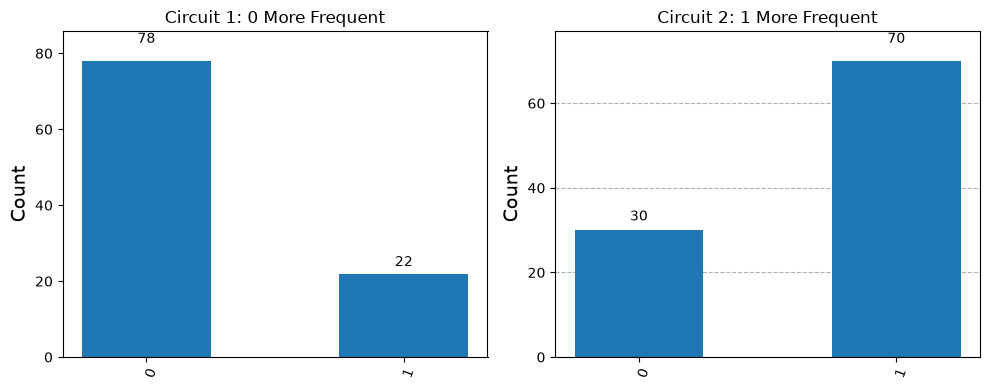

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_histogram(
    counts_0,
    ax=axes[0]
)
axes[0].set_title("Circuit 1: 0 More Frequent")

plot_histogram(
    counts_1,
    ax=axes[1]
)
axes[1].set_title("Circuit 2: 1 More Frequent")

plt.tight_layout()
plt.show()


In [13]:

import pandas as pd

comparison = pd.DataFrame({
    "Circuit": ["Circuit 1", "Circuit 2"],
    "Rotation angle": ["π/3", "2π/3"],
    "Predicted P(0)": ["75%", "25%"],
    "Predicted P(1)": ["25%", "75%"],
    "Actual counts": [
        str(counts_0),
        str(counts_1)
    ]
})

display(comparison)


,Circuit,Rotation angle,Predicted P(0),Predicted P(1),Actual counts
0,Circuit 1,π/3,75%,25%,"{'0': 78, '1': 22}"
1,Circuit 2,2π/3,25%,75%,"{'1': 70, '0': 30}"
